In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as snb
from tqdm import tqdm 
import os
from utils import gather_multi_benchmark_results,\
            gather_serial_benchmark_results,\
            plot_multithreading_benchmark_results,\
            gather_multinode_benchmark_results,\
            plot_multinode_benchmark_results \
            ,gather_multiprocthread_benchmark_results, \
            plot_multiprocthread_benchmark_results, \
            gather_curves_results, _plot_validation_curve

# Training Analysis

In [2]:
SERIAL_PATH = r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\serial\_benchmark\model_training\baseline_model_serial_benchmark.csv'
MULTITHREAD_INTRAOP_PATH = r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multithreading_intraop\_benchmark\model_training'
MULTITHREAD_INTEROP_PATH = r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multithreading_interop\_benchmark\model_training'
MULTITHREAD_INTERINTRA_PATH = r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multithreading_inta+inter\_benchmark\model_training'

df_serial = gather_serial_benchmark_results(SERIAL_PATH,'serial')
df_interop = gather_multi_benchmark_results(MULTITHREAD_INTEROP_PATH,'interop')
df_intraop = gather_multi_benchmark_results(MULTITHREAD_INTRAOP_PATH,'intraop')
df_interintra = gather_multi_benchmark_results(MULTITHREAD_INTERINTRA_PATH,'inter+intra')
# multithreading 
df_multithreading = pd.concat([df_interop,df_intraop,df_interintra],ignore_index=True)


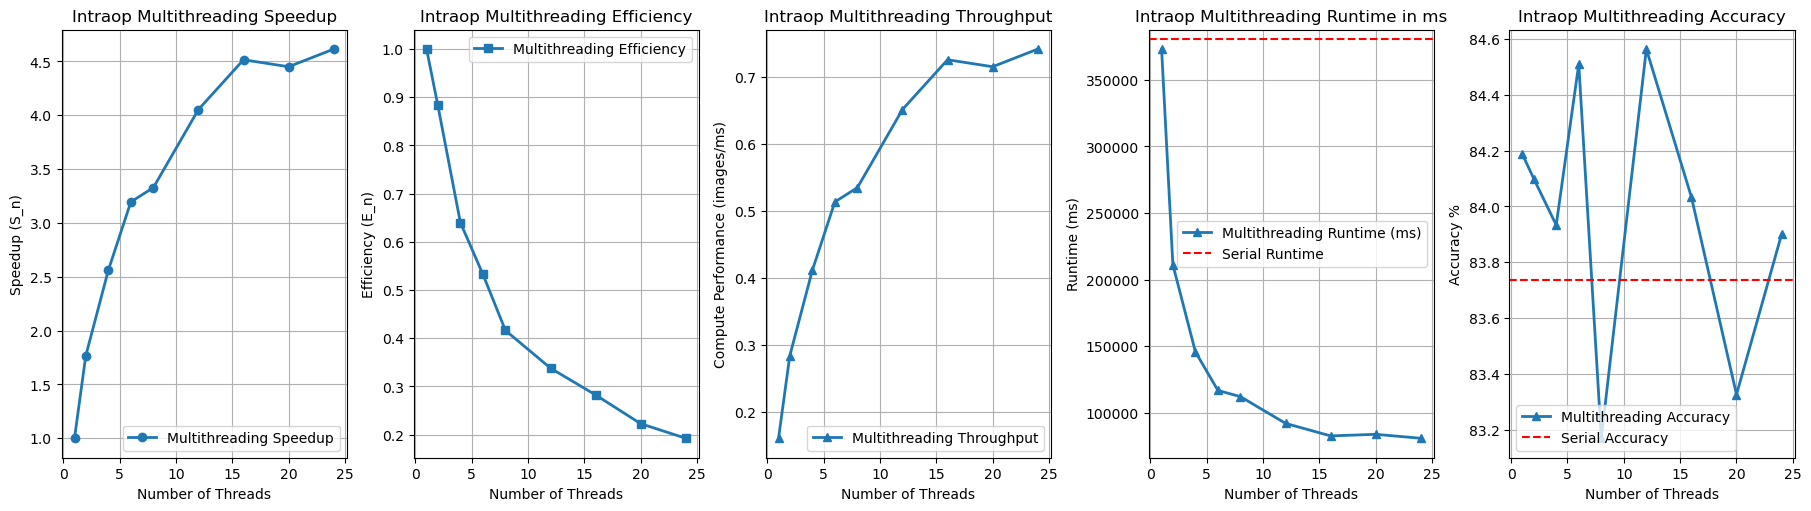

In [4]:

plot_multithreading_benchmark_results(df_serial, df_multithreading, 'Intraop') # change to 'Interop' or 'Inter+Intra' for other plots

# Multinode

In [3]:
MULTINODE_DIRS = [
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multinode_ddp\1task\_benchmark\2nodes_ddp_1task',
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multinode_ddp\2task\_benchmark\2nodes_ddp',
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multinode_ddp\4task\_benchmark\2nodes_ddp',
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\multinode_ddp\8task\_benchmark\2nodes_ddp'
]

df_multinode = gather_multinode_benchmark_results(MULTINODE_DIRS,'multinode')


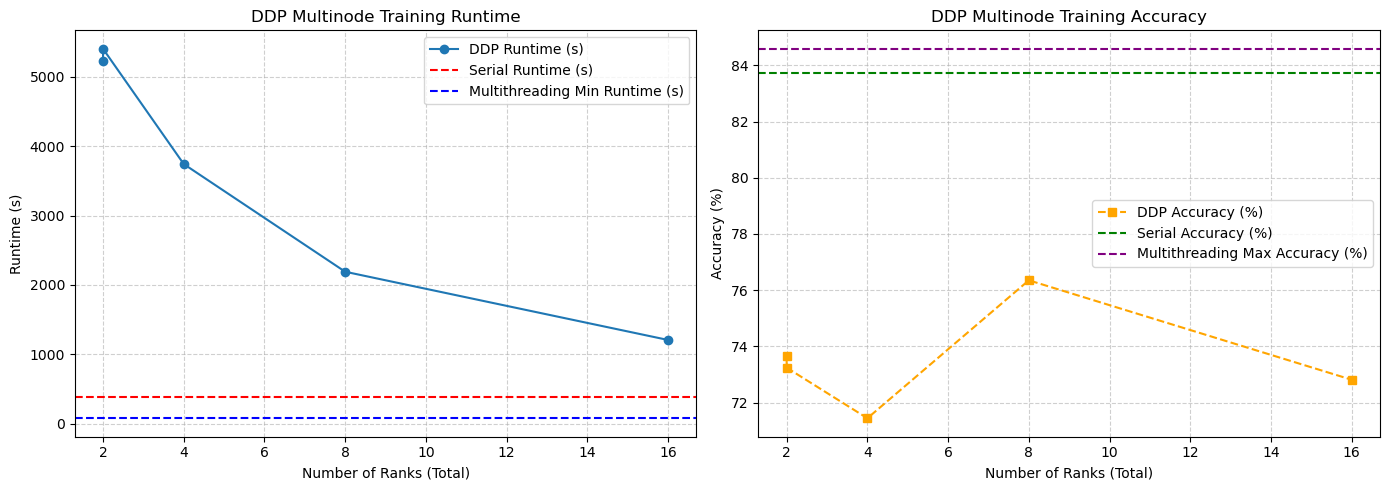

In [ ]:


plot_multinode_benchmark_results(df_multinode, df_serial, df_multithreading)


# Multiprocessing + Multithreading

In [4]:
MULTIPROCTHREAD_DIRS = [
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\single_node_mpi_ddp\_benchmark\1node_ddp_2proc_12threads',
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\single_node_mpi_ddp\_benchmark\1node_ddp_4proc_6threads',
    r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\model_training_benchmark\single_node_mpi_ddp\_benchmark\1node_ddp_8proc_3threads',
]



df_multiprocthread = gather_multiprocthread_benchmark_results(MULTIPROCTHREAD_DIRS,'multiprocthread')
print(df_multiprocthread)

   num_ranks  num_threads     runtime_ms   accuracy
0          2           12  474347.966922  73.980003
1          4            6   35289.881046  71.010002
2          8            3   27200.872828  75.660004


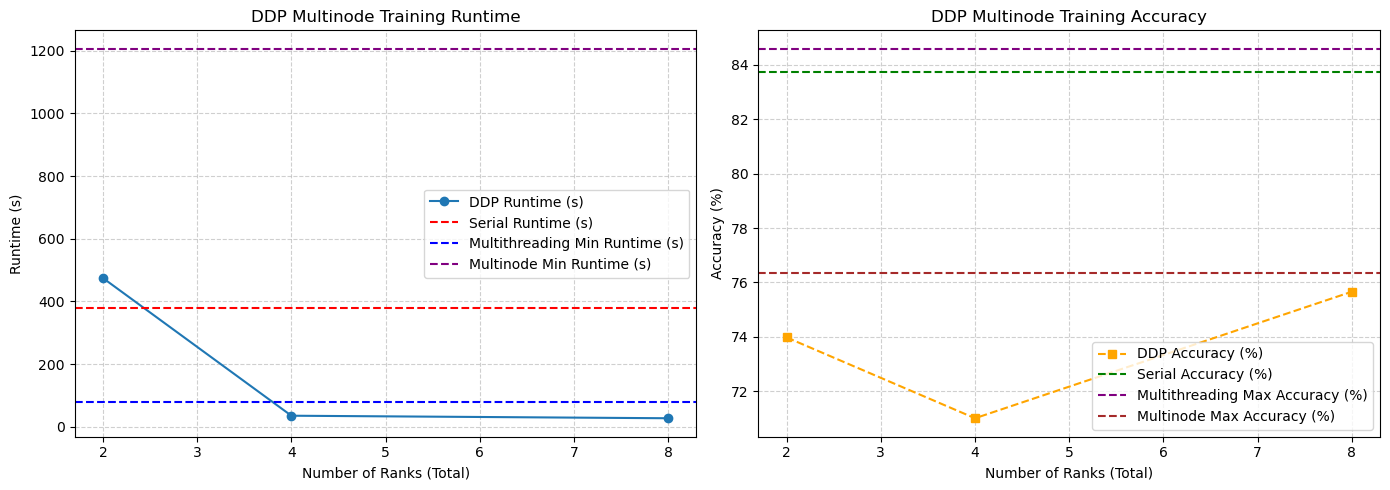

In [5]:
plot_multiprocthread_benchmark_results(df_multiprocthread, df_serial, df_multithreading, df_multinode)

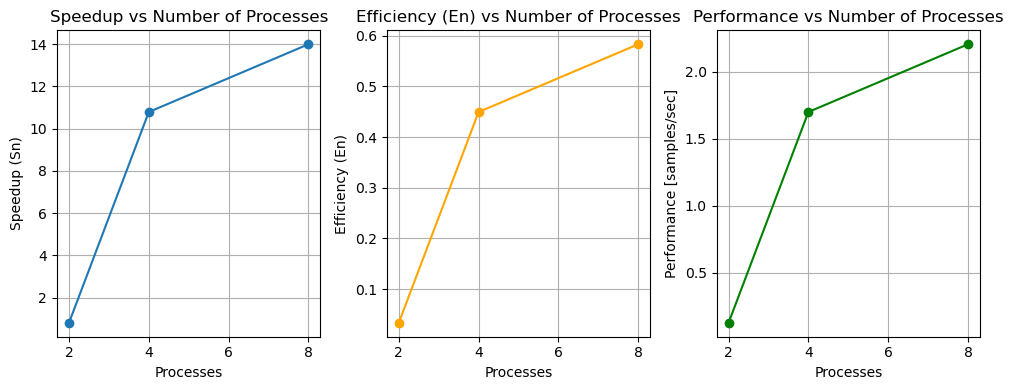

In [28]:
df_multiprocthread['Sn'] = df_serial['runtime_ms'].values / df_multiprocthread['runtime_ms'].values
df_multiprocthread['En'] = df_multiprocthread['Sn'] / (df_multiprocthread['num_ranks'] * df_multiprocthread['num_threads'])
df_multiprocthread['P_n'] =  60000 / df_multiprocthread["runtime_ms"]


df_multinode['Sn'] = df_serial['runtime_ms'].values / df_multinode['runtime_ms'].values
df_multinode['En'] = df_multinode['Sn'] / (df_multinode['num_ranks'] * df_multinode['num_threads'])
df_multinode['P_n'] =  60000 / df_multinode["runtime_ms"]

def plot_metrics(df: pd.DataFrame):
    fig, axs = plt.subplots(1, 3, figsize=(10, 4))

    axs[0].plot(df['num_ranks'] , df['Sn'], marker='o')
    axs[0].set_title('Speedup vs Number of Processes')
    axs[0].set_xlabel('Processes')
    axs[0].set_ylabel('Speedup (Sn)')
    axs[0].grid(True)

    axs[1].plot(df['num_ranks'], df['En'], marker='o', color='orange')
    axs[1].set_title('Efficiency (En) vs Number of Processes')
    axs[1].set_xlabel('Processes')
    axs[1].set_ylabel('Efficiency (En)')
    axs[1].grid(True)

    axs[2].plot(df['num_ranks'], df['P_n'], marker='o', color='green')
    axs[2].set_title('Performance vs Number of Processes')
    axs[2].set_xlabel('Processes')
    axs[2].set_ylabel('Performance [samples/sec]')
    axs[2].grid(True)

    plt.tight_layout()
    plt.show()

plot_metrics(df_multiprocthread)

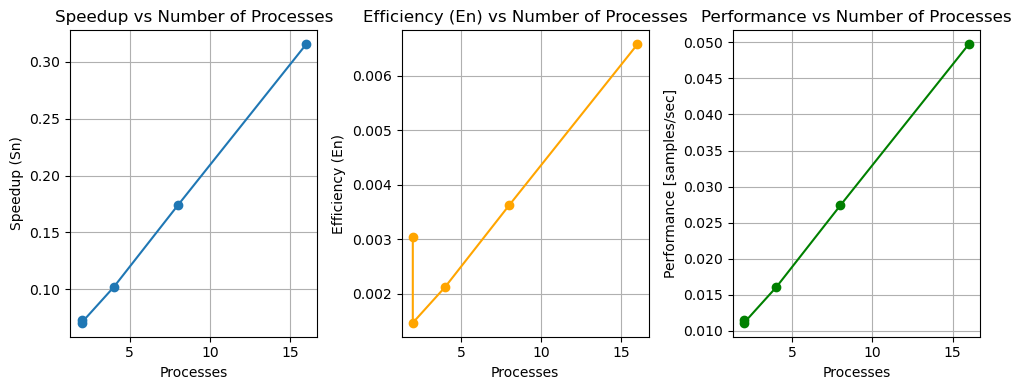

In [29]:
plot_metrics(df_multinode)

# Validation Curve Analysis

In [2]:
VALIDATION_PATHS = [
    (r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\validation_curve_benchmark\_benchmark\validation_curve\batch_size_ddp2proc_12threads','batch_size'),
    (r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\validation_curve_benchmark\_benchmark\validation_curve\learning_rate_ddp2proc_12threads','learning_rate'),
    (r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\validation_curve_benchmark\_benchmark\validation_curve\num_epochs_ddp2proc_12threads','num_epochs'),
    (r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\validation_curve_benchmark\_benchmark\validation_curve\optimizer_ddp2proc_12threads','optimizer')
]

validation_df = gather_curves_results(VALIDATION_PATHS ,'test')


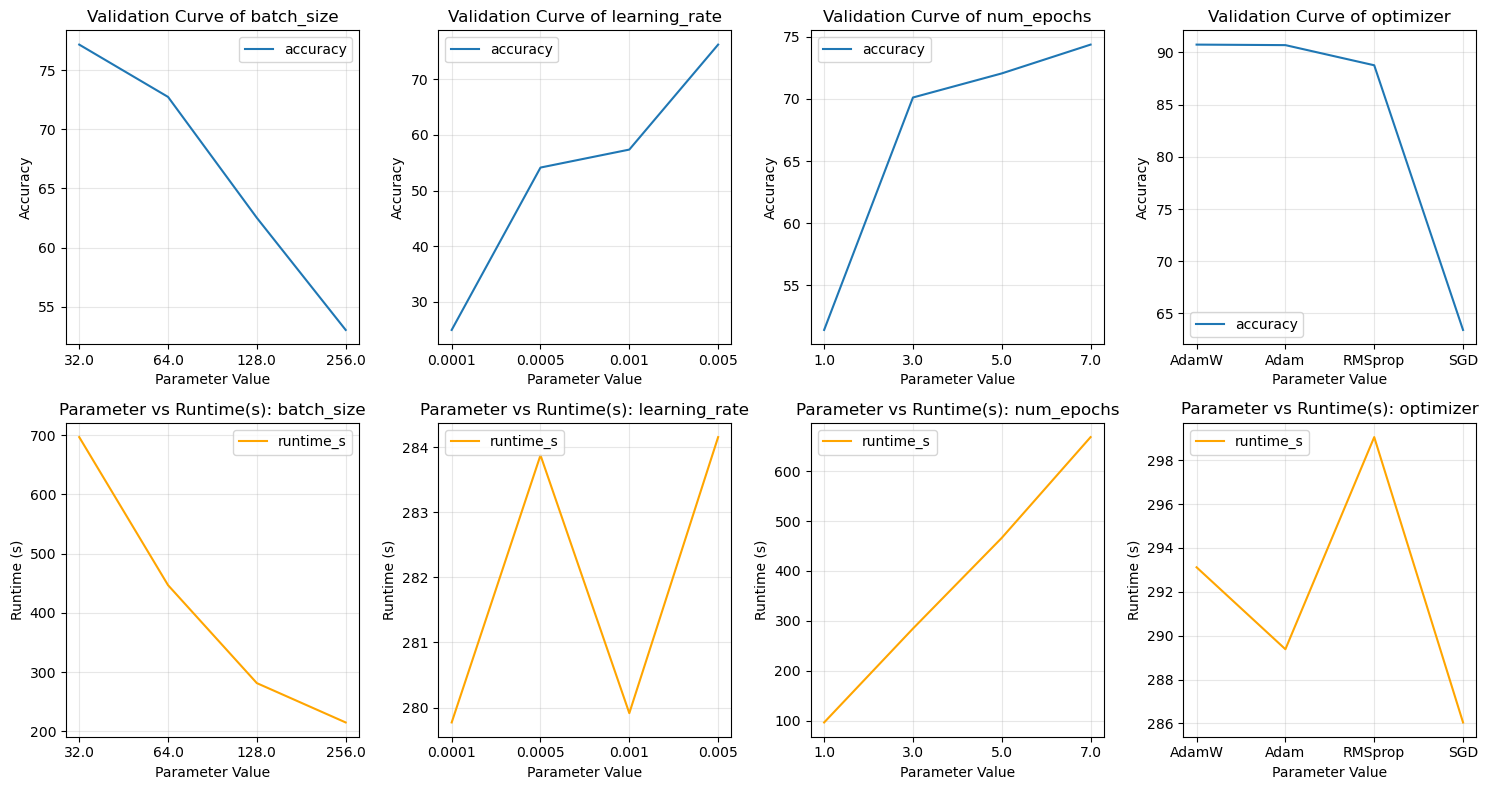

In [3]:
_plot_validation_curve(validation_df)

In [5]:
validation_df

,num_ranks,num_threads,runtime_ms,accuracy,parameter,parameter_value
0,2,12,281270.698755,62.509998,batch_size,128.0
1,2,12,214867.271861,53.020000,batch_size,256.0
2,2,12,696726.630074,77.180000,batch_size,32.0
3,2,12,446709.700665,72.750000,batch_size,64.0
4,2,12,279771.576343,24.940001,learning_rate,0.0001
5,2,12,283875.543885,54.130001,learning_rate,0.0005
6,2,12,279914.185782,57.360001,learning_rate,0.001
7,2,12,284153.590000,76.230003,learning_rate,0.005
8,2,12,96592.592267,51.400002,num_epochs,1.0
9,2,12,284561.704606,70.120003,num_epochs,3.0


# Learning Curve

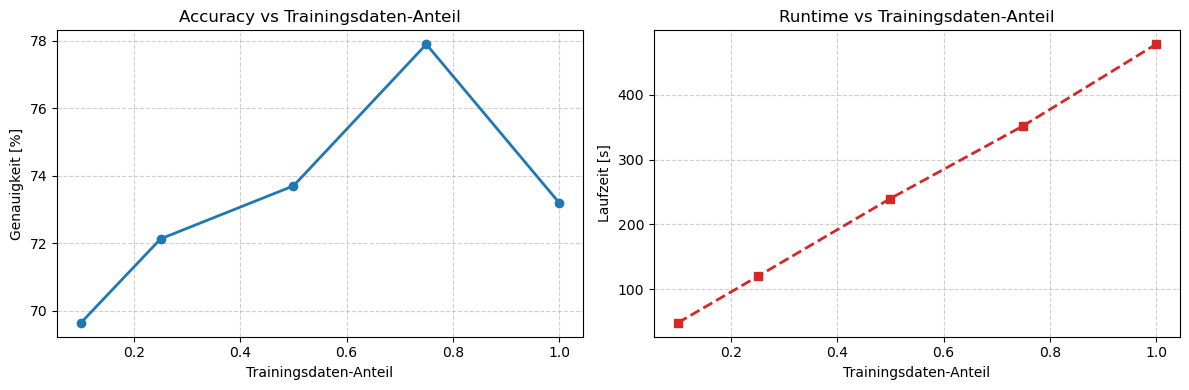

In [28]:
LEARNING_CURVE_PATH = r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\learning_curve_benchmark\_benchmark\learning_curve'

def _gather_learning_curve(dir_p: str) -> pd.DataFrame:
    dirs = os.listdir(dir_p)
    df_list = []
    for dir in dirs:
        file_name = os.listdir(os.path.join(dir_p,dir))[0]
        if file_name.endswith('.csv'):
                file_path = os.path.join(dir_p,dir,file_name)
                df = pd.read_csv(file_path)
                #df['configuration'] = os.path.basename(dir_path)
                df_list.append(df)
    combined_df = pd.concat(df_list, ignore_index=True)
    #combined_df['benchmark_type'] = label
    return combined_df

def plot_learning_curve(df):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Left subplot: Accuracy
    axes[0].plot(df["train_fraction"], df["accuracy"], marker="o", color="tab:blue", linewidth=2)
    axes[0].set_xlabel("Trainingsdaten-Anteil")
    axes[0].set_ylabel("Genauigkeit [%]")
    axes[0].set_title("Accuracy vs Trainingsdaten-Anteil")
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Right subplot: Runtime
    axes[1].plot(df["train_fraction"], df["runtime_ms"] / 1000, marker="s", linestyle="--", color="tab:red", linewidth=2)
    axes[1].set_xlabel("Trainingsdaten-Anteil")
    axes[1].set_ylabel("Laufzeit [s]")
    axes[1].set_title("Runtime vs Trainingsdaten-Anteil")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()
plot_learning_curve(_gather_learning_curve(LEARNING_CURVE_PATH))

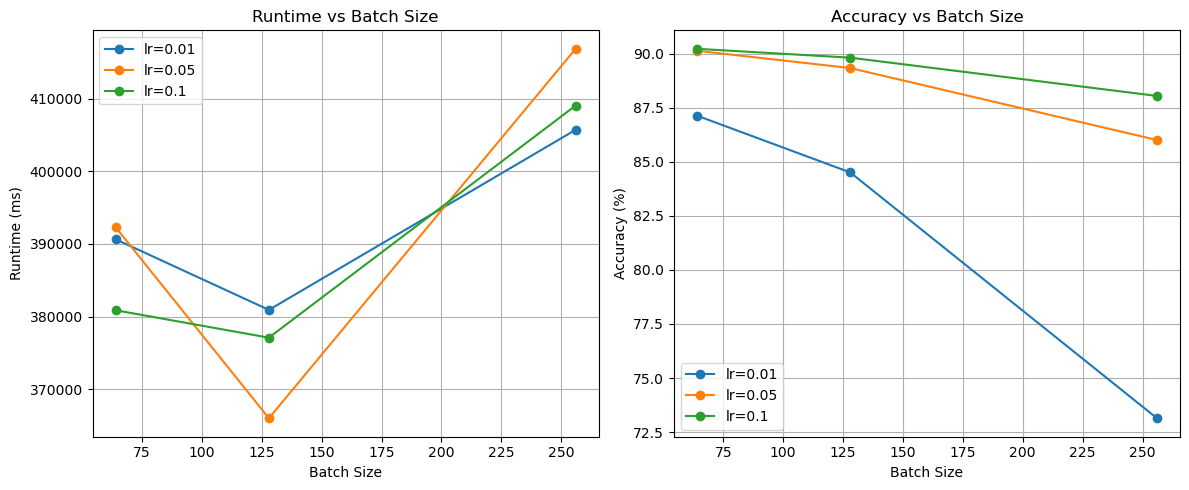

In [9]:
HYPERPARAMETER_SEARCH = r'C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\hyperparameter_tuning_benchmark\_benchmark\hyperparam_search'

def _gather_hyper_results(dir: str) -> pd.DataFrame:
    files = os.listdir(dir)
    df_list = []
    for file in files:
        file_name = os.path.join(dir,file)
        df = pd.read_csv(file_name)
        df_list.append(df)
    combined_df = pd.concat(df_list, ignore_index=True)
    #combined_df['benchmark_type'] = label
    return combined_df
hyper_df = _gather_hyper_results(HYPERPARAMETER_SEARCH)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---- Left plot: Runtime ----
for lr, group in hyper_df.groupby("lr"):
    group.sort_values('batch_size',ascending=True,inplace=True)
    axes[0].plot(group["batch_size"], group["runtime_ms"], marker='o', label=f"lr={lr}")
axes[0].set_title("Runtime vs Batch Size")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Runtime (ms)")
axes[0].legend()
axes[0].grid(True)

# ---- Right plot: Accuracy ----
for lr, group in hyper_df.groupby("lr"):
    group.sort_values('batch_size',ascending=True,inplace=True)
    axes[1].plot(group["batch_size"], group["accuracy"], marker='o', label=f"lr={lr}")
axes[1].set_title("Accuracy vs Batch Size")
axes[1].set_xlabel("Batch Size")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [7]:
for lr, group in hyper_df.groupby("lr"):
    print(lr)
    print(group)

0.01
     lr  batch_size  num_epochs     runtime_ms  accuracy
0  0.01         128           5  380909.407259     84.51
1  0.01         256           5  405710.024472     73.14
2  0.01          64           5  390641.566444     87.14
0.05
     lr  batch_size  num_epochs     runtime_ms  accuracy
3  0.05         128           5  365988.805475     89.34
4  0.05         256           5  416865.746363     86.01
5  0.05          64           5  392310.175010     90.14
0.1
    lr  batch_size  num_epochs     runtime_ms  accuracy
6  0.1         128           5  377085.201834     89.82
7  0.1         256           5  409046.886798     88.05
8  0.1          64           5  380862.701426     90.23
